In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [2]:
df = pd.read_csv("Housing.csv")

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [3]:
#Understand and inspect the dataset Code

# Display number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns)

# Display data types and information
print("\nDataset Information:")
df.info()

# Display statistical summary
print("\nSummary Statistics:")
df.describe()

Dataset Shape: (545, 13)

Column Names:
Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea       

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [4]:
#Check missing values and duplicate records

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Duplicate Records:
0


In [5]:
# Remove duplicate rows
df = df.drop_duplicates()

# Convert area and price into numeric values
df["area"] = pd.to_numeric(df["area"], errors="coerce")
df["price"] = pd.to_numeric(df["price"], errors="coerce")

# Remove rows with missing area or price
df = df.dropna(subset=["area", "price"])

# Remove invalid values
df = df[(df["area"] > 0) & (df["price"] > 0)]

print("Dataset after cleaning:")
print(df.shape)

print("\nMissing values after cleaning:")
print(df[["area", "price"]].isnull().sum())

Dataset after cleaning:
(545, 13)

Missing values after cleaning:
area     0
price    0
dtype: int64


In [6]:
# Select input feature(x) and target (y)

# Select input feature
X = df[["area"]]

# Select target variable
y = df["price"]

print("Input Feature (X):")
print(X.head())

print("\nTarget Variable (Y):")
print(y.head())

Input Feature (X):
   area
0  7420
1  8960
2  9960
3  7500
4  7420

Target Variable (Y):
0    13300000
1    12250000
2    12250000
3    12215000
4    11410000
Name: price, dtype: int64


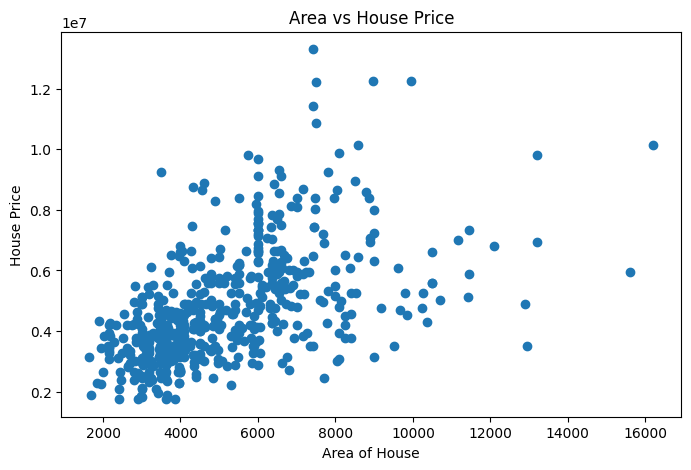

In [7]:
#Visualize the relationship using a scatter plot

plt.figure(figsize=(8, 5))

plt.scatter(df["area"], df["price"])

plt.xlabel("Area of House")
plt.ylabel("House Price")
plt.title("Area vs House Price")

plt.show()

In [8]:
#Split the dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

Training Data: 436
Testing Data: 109


In [9]:
#Train the Linear Regression model

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Get coefficient and intercept
m = model.coef_[0]
c = model.intercept_

print("Coefficient (Slope):", m)
print("Intercept:", c)

print("\nLinear Regression Equation:")
print("Price =", m, "* Area +", c)

Coefficient (Slope): 425.72984193878284
Intercept: 2512254.2639593435

Linear Regression Equation:
Price = 425.72984193878284 * Area + 2512254.2639593435


In [10]:
#Predict house prices using testing data

# Predict prices using testing data
y_pred = model.predict(X_test)

# Compare actual and predicted prices
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print(comparison.head(10))

   Actual Price  Predicted Price
0       4060000     5.024060e+06
1       6650000     5.279498e+06
2       3710000     4.232203e+06
3       6440000     4.640903e+06
4       2800000     4.198144e+06
5       4900000     5.373159e+06
6       5250000     6.139473e+06
7       4543000     4.636646e+06
8       2450000     3.891619e+06
9       3353000     3.661725e+06


In [11]:
#Evaluate the model using performance metrics

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 1474748.1337969352
Mean Squared Error (MSE): 3675286604768.185
Root Mean Squared Error (RMSE): 1917103.7021424233
R2 Score: 0.27287851871974644


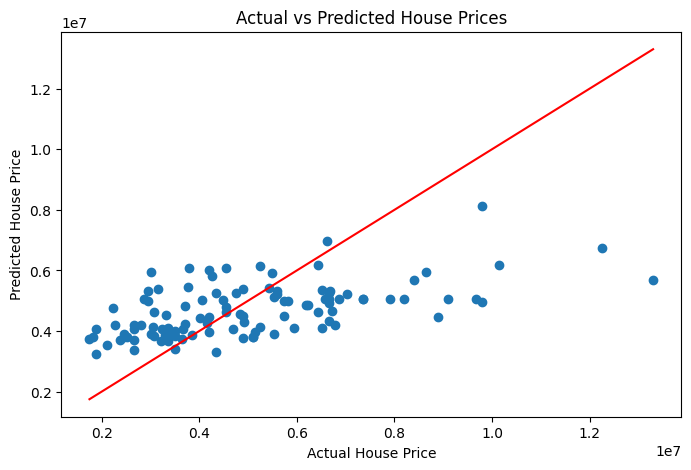

In [12]:
#Plot actual price vs predicted price

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

# Draw reference line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red"
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [13]:
# Select a new house area within the training data range
new_area = X_train["area"].median()

# Predict its price
new_price = model.predict(pd.DataFrame({
    "area": [new_area]
}))

print("New House Area:", new_area)
print("Predicted House Price:", new_price[0])

New House Area: 4500.0
Predicted House Price: 4428038.552683867


**Conclusion:**
In this activity, I developed a Simple Linear Regression model to predict house prices using the Housing Price Prediction dataset from Kaggle. I selected area as the input feature and price as the target variable. I divided the dataset into 80% training data and 20% testing data. The model was trained using Linear Regression and evaluated using MAE, MSE, RMSE and R² score. I also visualized the relationship between area and price and compared actual and predicted prices. Finally, I used the trained model to predict the price of a new house. The model has limitations because house prices depend on other factors such as location, bedrooms and facilities, which were not included in this single-feature model.